# Yellow rust yield loss in Egyptian wheat cultivars (Sharkiya)

This notebook reproduces, with simpest, the FraNchEstYN R vignette
"Yellow rust on wheat in Egypt" (`vignettes/case-study-egypt-yellow-rust.Rmd`
in [GeoModelLab/FraNchEstYN](https://github.com/GeoModelLab/FraNchEstYN);
a rendered copy is `estimating_yield_loss.html` in this folder). It is the
first simpest case where the simulated yield loss can be set against a
**measured** loss.

**The trial.** Omara, El-Naggar, Abd El Malik and Ketta (2016), *Losses
assessment in some Egyptian wheat cultivars caused by stripe rust pathogen
(Puccinia striiformis)*, Egypt. J. Phytopathol. 44(1):191–203
(`SharkiyaData/paper/`; the R package cites it as 2018). Seven bread-wheat
cultivars were grown at Kafr El-Hamam Agricultural Research Station,
Sharkiya (30.615 N, 31.515 E), in 2013/14 and 2014/15, in a split-plot
design: each cultivar was either **protected** (three sprays of Sumi-8 from
disease onset) or **infected** (spreader rows inoculated at booting). Stripe
(yellow) rust severity was scored weekly as percent leaf area with pustules
(modified Cobb scale, Peterson et al. 1948), and grain yield was measured in
both treatments. The measured loss is the paper's "estimated loss",
`(1 − Y_infected / Y_protected) × 100` (Calpouzos et al. 1976).

**The workflow** has the vignette's three steps:

1. **Crop**: calibrate the crop on the most susceptible cultivar (Sids-12)
   against light interception and the protected-plot yield, with the disease
   switched off.
2. **Disease**: keep the crop fixed and calibrate the yellow-rust parameters on
   Sids-12 against severity and the infected-plot yield, with the light
   stealer as the only damage mechanism.
3. **Cultivars**: keep the disease fixed and fit, per cultivar, only the
   radiation use efficiency and the varietal resistance.

A last section compares simulated and measured loss for all fourteen
cultivar-seasons.

## Same method as the R vignette

The notebook follows the vignette's settings and the FraNchEstYN C# engine
the R package runs:

- **Optimizer.** `optimizer="multistart-simplex"` is simpest's port of the
  C# calibration library (`UNIMI.optimizer.MultiStartSimplex`): its random
  generator, starting vertices, simplex moves, stopping rule, bounds penalty
  and final sort, checked bit for bit against `optimizerSimplex.dll`. As in the
  R package: 3 simplexes (`R/Main.R`), 999 iterations per simplex (the
  vignette), tolerance 1e-12 (C# `Program.cs`).
- **Objective.** `compute_rmse` is the port of the C# objective, rounded to
  three decimals as in C#, and gives the C# value for the same parameters
  (checked against the C# engine). As in C#, an observation dated after the
  simulated maturity is compared with zero output, so a crop that matures
  before the harvest date gets a zero yield with a ×1000 penalty.
- **Parameters.** The canonical wheat and yellow-rust sets in simpest's JSON
  files are the R package's `cropParameters$wheat` and
  `diseaseParameters$yellow_rust` (same values, bounds, flags and order).
  Step 1 widens the `CycleLength` bounds to 3000–4500 °C d, as the vignette
  does, and calibrates every flagged crop parameter.
- **Model.** With the same parameters and weather, a simpest run reproduces
  the C# daily output (light interception, biomass, yields, severity) to
  about 1e-6 relative, the precision C# writes.

One difference is unavoidable: C# seeds the generator from
`new Random().Next()`, so each C# run starts from different vertices and ends
on different parameters. Here the seed is fixed (`seed=1`), which makes the run
reproducible; it is one possible C# run, not *the* C# result. C# also
computes in single precision, so even with the same seed a long search can
drift apart from the C# one.

## What the results can and cannot support

- **The simulated loss is fitted, not predicted.** Both yields of every
  cultivar-season are calibration targets (step 1 the protected yield of
  Sids-12, step 2 its infected yield, step 3 both yields of each cultivar).
  The comparison in section 6 is a check of how well one parameter set per
  cultivar can reproduce both seasons, not an independent test.
- **Sowing date is assumed.** DOY 300 (27 October), as in the vignette; the
  paper does not give it.
- **The `fint` column is a placeholder.** It holds 1.0 on DOY 91 and 0.3 on
  DOY 135 for every cultivar and season, not a measurement.
- **Weather is gridded.** NASA POWER (MERRA-2) daily Tmax, Tmin and rain, the
  vignette's query. Radiation is not in it and is estimated from the
  temperature range (Hargreaves–Samani); hourly humidity and leaf wetness are
  synthesised from the daily values.

In [1]:
import copy
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from simpest.models import franchestyn as fr
from simpest.models import fr_diagnostics as diag

DATA = Path("SharkiyaData")
START_YEAR, END_YEAR = 2013, 2015   # as in the vignette: sowings in 2013 and 2014
SEASONS = [2013, 2014]              # GrowingSeason = sowing year
SUSCEPTIBLE = "sids12"              # the most susceptible cultivar (paper, Table 1)
HARVEST_DOY = 135                   # date of the yield observations in the dataset
LATITUDE = 30.6150167               # latitude of the vignette's NASA POWER weather

# Calibration settings shared by the three steps, as in the R package:
# 3 simplexes (R/Main.R), 999 iterations (vignette), ftol 1e-12 (C# Program.cs).
# seed replaces the unseeded C# draw; n_jobs runs the simplexes in parallel
# and does not change the result.
CALIB = dict(optimizer="multistart-simplex", n_restarts=3, max_iter=999, ftol=1e-12,
             seed=1, n_jobs=3)

## 1. Data

Everything is read from `SharkiyaData/`, laid out like the Indiana data folder:

| file | content | source |
|---|---|---|
| `site/site.csv` | latitude, sowing DOY, CO₂ per season (also the torchcrop site table) | written by `tools/fetch_power_torchcrop_dataset.py`; not used here (its latitude is rounded to 30.615, the notebook uses the vignette's 30.6150167) |
| `weather/sharkiya_2013_2015.csv` | daily `tmax`, `tmin`, `prec`, 2013–2015 | NASA POWER daily API, `T2M_MAX`, `T2M_MIN`, `PRECTOTCORR`, the vignette's query |
| `management/management.csv` | crop, sowing DOY 300 for all years | the vignette's assumption |
| `disease/disease.csv` | severity (%) per cultivar and date, `fint` placeholder | `data-raw/reference_egypt.csv` of the R package, digitised from the paper |
| `yield/yield.csv` | protected (`yieldAttainable`) and infected (`yieldActual`) grain yield, kg ha⁻¹ | same file; the paper's ardab feddan⁻¹ × 150 kg / 0.42 ha (Tables 2 and 3) |

In [2]:
weather_df = pd.read_csv(DATA / "weather" / "sharkiya_2013_2015.csv")
management_df = pd.read_csv(DATA / "management" / "management.csv")
disease_obs = pd.read_csv(DATA / "disease" / "disease.csv")
yield_obs = pd.read_csv(DATA / "yield" / "yield.csv")

# One reference table, as FraNchEstYN expects it: severity, fint and yields by year and DOY.
ref_df = disease_obs.merge(yield_obs, on=["site", "variety", "year", "DOY"], how="left")

yield_obs["season"] = yield_obs["year"] - 1     # yields are reported in the harvest year
yield_obs["loss_measured"] = (1 - yield_obs["yieldActual"] / yield_obs["yieldAttainable"]) * 100
VARIETIES = list(disease_obs["variety"].unique())

display(weather_df.head(3))
display(management_df)
yield_obs.pivot(index="variety", columns="season", values="loss_measured").round(1).loc[VARIETIES]

,date,tmax,tmin,prec
0,2013-01-01,20.49,7.10,0.00
1,2013-01-02,21.39,6.21,0.00
2,2013-01-03,22.32,9.08,0.07


,crop,variety,resistance,sowingDOY,year
0,wheat,Generic,0,300,All


season,2013,2014
variety,,
sids12,55.4,58.3
gem11,53.4,57.0
gem7,42.8,46.6
sids13,30.8,35.4
sids1,35.0,39.4
gem9,24.1,26.9
gem10,18.9,23.9


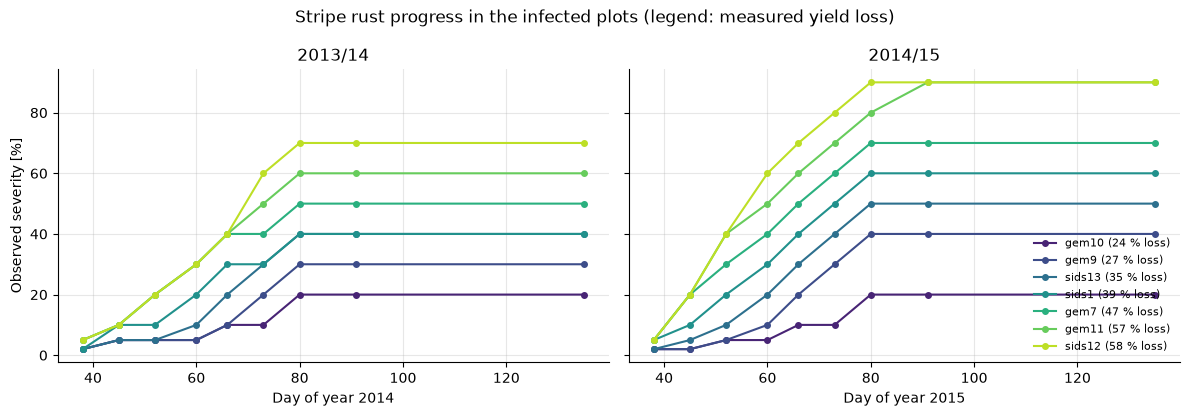

In [3]:
# Observed severity per cultivar and season. Cultivars are ordered by measured
# loss (2013/14), so the colour ramp runs from the least to the most damaged one.
order = (yield_obs[yield_obs["season"] == 2013].sort_values("loss_measured")["variety"].tolist())
colors = dict(zip(order, plt.get_cmap("viridis")(np.linspace(0.1, 0.9, len(order)))))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, season in zip(axes, SEASONS):
    for variety in order:
        obs = disease_obs[(disease_obs["variety"] == variety) & (disease_obs["year"] == season + 1)]
        loss = yield_obs.query("variety == @variety and season == @season")["loss_measured"].iloc[0]
        ax.plot(obs["DOY"], obs["disease"], marker="o", ms=4, color=colors[variety],
                label=f"{variety} ({loss:.0f} % loss)")
    ax.set_title(f"{season}/{season + 1 - 2000:02d}")
    ax.set_xlabel(f"Day of year {season + 1}")
    ax.grid(alpha=0.3)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
axes[0].set_ylabel("Observed severity [%]")
axes[1].legend(frameon=False, fontsize=8, loc="lower right")
fig.suptitle("Stripe rust progress in the infected plots (legend: measured yield loss)")
fig.tight_layout()
plt.show()

## 2. Shared run settings

All runs use the internal FraNchEstYN crop model (`crop_model_df=None`), daily
weather and no fungicide model: the protected plots are represented by the
attainable (disease-free) yield, not by a simulated spray. The management
table is filtered by cultivar, so each run gets it with that cultivar's name.

In [4]:
def make_config(variety, **settings):
    """Run settings shared by every run in this notebook."""
    return fr.FranchestynConfig(
        site="Sharkiya", variety=variety, disease="disease", fungicide_type=None,
        latitude=LATITUDE, **settings,
    )


def run(config, variety):
    return fr.run_franchestyn(
        START_YEAR, END_YEAR, config, weather_df, management_df.assign(variety=variety), None, ref_df,
    )


def obs_dates(df):
    return diag.reference_dates(df)

## 3. Step 1 — crop calibration (Sids-12)

As in the vignette, the crop parameters flagged for calibration in the
canonical wheat set are calibrated (`calibration_variable="crop"`):
`TbaseCrop`, `CycleLength`, `FloweringStart`, `HalfIntGrowth`,
`HalfIntSenescence`, `SlopeGrowth`, `SlopeSenescence` and
`PartitioningMaximum`. The `CycleLength` bounds are widened to 3000–4500 °C d
"to harvest around mid-May" (vignette). The targets are the two protected-plot
yields of Sids-12 and the `fint` placeholders. The disease is simulated (the
vignette passes the yellow-rust set), but a crop calibration only scores
disease-free quantities, so it does not affect this step.

The yields are dated DOY 135. If the simulated crop matures before that day,
the C# objective compares them with zero output and multiplies the error by
1000, which keeps the calibrated maturity after DOY 135; the cell prints the
maturity dates.

In [5]:
crop_cfg = make_config(SUSCEPTIBLE, disease_type="yellow_rust", calibration_variable="crop", **CALIB)
crop_cfg.crop_parameters["CycleLength"].update(min=3000.0, max=4500.0)   # vignette, step 1

crop_res = run(crop_cfg, SUSCEPTIBLE)
crop_best = crop_res["outputs"]["summary"]["best_params"]
fr.apply_best_params(crop_cfg, crop_best)
print("Objective (RMSE):", crop_res["outputs"]["summary"]["rmse"])

crop_sim = diag.simulation_frame(crop_res)
for season, s in crop_sim.groupby("GrowingSeason"):
    maturity = s["Date"].max()
    after = maturity.dayofyear >= HARVEST_DOY
    print(f"{season}/{season + 1 - 2000:02d}: maturity {maturity:%d %b %Y}, yield observation on "
          f"DOY {HARVEST_DOY} {'compared with the simulated yield' if after else 'compared with zero (x1000)'}")
diag.bound_check(crop_best, {"crop": crop_cfg.crop_parameters}).round(4)

- Calibrating 8 parameters with the C# multi-start simplex (3 simplexes, 999 iterations, seed 1).
- Parameters:
['crop_TbaseCrop', 'crop_CycleLength', 'crop_FloweringStart', 'crop_HalfIntGrowth', 'crop_HalfIntSenescence', 'crop_SlopeGrowth', 'crop_SlopeSenescence', 'crop_PartitioningMaximum']


[Parallel(n_jobs=3)]: Using backend LokyBackend with 3 concurrent workers.


[Parallel(n_jobs=3)]: Done   3 out of   3 | elapsed:   59.9s finished



Best RMSE: 4.9370
{'crop_TbaseCrop': -0.9923074875185156, 'crop_CycleLength': 4231.3535586122325, 'crop_FloweringStart': 77.45585742106645, 'crop_HalfIntGrowth': 25.134663109132003, 'crop_HalfIntSenescence': 88.56253100680013, 'crop_SlopeGrowth': 0.019770118623231615, 'crop_SlopeSenescence': 0.004164064745194601, 'crop_PartitioningMaximum': 0.9935538000369523}
Objective (RMSE): 4.937
2013/14: maturity 23 May 2014, yield observation on DOY 135 compared with the simulated yield
2014/15: maturity 31 May 2015, yield observation on DOY 135 compared with the simulated yield


,value,min,max,position,at_bound
parameter,,,,,
crop_TbaseCrop,-0.9923,-1.000,5.00,0.0013,lower
crop_CycleLength,4231.3536,3000.000,4500.00,0.8209,
crop_FloweringStart,77.4559,50.000,85.00,0.7845,
crop_HalfIntGrowth,25.1347,20.000,35.00,0.3423,
crop_HalfIntSenescence,88.5625,50.000,99.00,0.7870,
crop_SlopeGrowth,0.0198,0.001,0.02,0.9879,upper
crop_SlopeSenescence,0.0042,0.001,0.07,0.0459,lower
crop_PartitioningMaximum,0.9936,0.800,1.00,0.9678,upper


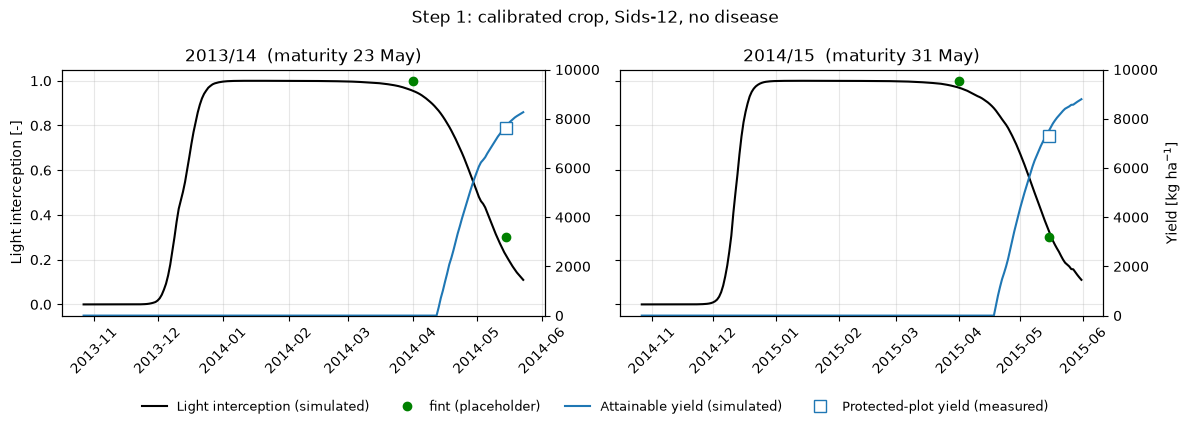

In [6]:
sus_ref = ref_df[ref_df["variety"] == SUSCEPTIBLE]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, season in zip(axes, SEASONS):
    s = crop_sim[crop_sim["GrowingSeason"] == season]
    r = sus_ref[sus_ref["year"] == season + 1]
    ax.plot(s["Date"], s["LightInterception"], color="black", lw=1.5, label="Light interception (simulated)")
    fi = r.dropna(subset=["fint"])
    ax.plot(obs_dates(fi), fi["fint"], "o", color="green", label="fint (placeholder)")
    ax2 = ax.twinx()
    ax2.plot(s["Date"], s["YieldAttainable"], color="#1f77b4", lw=1.5, label="Attainable yield (simulated)")
    y = r.dropna(subset=["yieldAttainable"])
    ax2.plot(obs_dates(y), y["yieldAttainable"], "s", color="#1f77b4", mfc="white", ms=8,
             label="Protected-plot yield (measured)")
    ax2.set_ylim(0, 10000)
    ax.set_title(f"{season}/{season + 1 - 2000:02d}  (maturity {s['Date'].max():%d %b})")
    ax.tick_params(axis="x", rotation=45)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Light interception [-]")
ax2.set_ylabel("Yield [kg ha$^{-1}$]")
handles = axes[0].get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
fig.legend(handles, [h.get_label() for h in handles], loc="lower center", ncol=4, frameon=False, fontsize=9)
fig.suptitle("Step 1: calibrated crop, Sids-12, no disease")
fig.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

## 4. Step 2 — disease calibration (Sids-12)

The crop is fixed at step 1. Following the vignette, the damage pathways other
than the light stealer are switched off, to avoid fitting four damage
coefficients to two yields: `AssimilateSappersDamage`, `RUEreducerDamage` and
`SenescenceAcceleratorDamage` are set to 0 and not calibrated, and
`OuterInoculumShapeRelease` is set to 1 (all four values from the vignette).
The other yellow-rust parameters flagged in `fr_disease_parameters.json`,
including `LightStealerDamage`, are calibrated against the severity of
Sids-12 and its infected-plot yield (`calibration_variable="disease"`).

In [7]:
dis_cfg = make_config(SUSCEPTIBLE, disease_type="yellow_rust", calibration_variable="disease", **CALIB)
dis_cfg.crop_parameters = copy.deepcopy(crop_cfg.crop_parameters)
fr.deactivate_calibration(dis_cfg.crop_parameters, list(dis_cfg.crop_parameters))
for name in ("AssimilateSappersDamage", "RUEreducerDamage", "SenescenceAcceleratorDamage"):
    dis_cfg.disease_parameters[name].update(value=0.0, calibration=False)   # vignette, step 2
dis_cfg.disease_parameters["OuterInoculumShapeRelease"]["value"] = 1.0       # vignette, step 2

dis_res = run(dis_cfg, SUSCEPTIBLE)
dis_best = dis_res["outputs"]["summary"]["best_params"]
fr.apply_best_params(dis_cfg, dis_best)
print("Objective (RMSE):", dis_res["outputs"]["summary"]["rmse"])
diag.bound_check(dis_best, {"disease": dis_cfg.disease_parameters}).round(3)

- Calibrating 17 parameters with the C# multi-start simplex (3 simplexes, 999 iterations, seed 1).
- Parameters:
['disease_OuterInoculumMax', 'disease_PathogenSpread', 'disease_WetnessDurationOptimum', 'disease_WetnessDurationMinimum', 'disease_DryCriticalInterruption', 'disease_Tmin', 'disease_Topt', 'disease_Tmax', 'disease_RelativeHumidityCritical', 'disease_Rain50Detachment', 'disease_RelativeHumidityNotLimiting', 'disease_HydroThermalTimeOnset', 'disease_CyclePercentageOnset', 'disease_LatencyDuration', 'disease_SporulationDuration', 'disease_LightStealerDamage', 'disease_OuterInoculumShapeParameter']


[Parallel(n_jobs=3)]: Using backend LokyBackend with 3 concurrent workers.
[Parallel(n_jobs=3)]: Done   3 out of   3 | elapsed:  2.0min finished



Best RMSE: 7.1420
{'disease_OuterInoculumMax': 0.07685872863145449, 'disease_PathogenSpread': 0.4441185999380918, 'disease_WetnessDurationOptimum': 14.152986353945659, 'disease_WetnessDurationMinimum': 9.56156420461105, 'disease_DryCriticalInterruption': 19.656033097983258, 'disease_Tmin': 2.560668511428121, 'disease_Topt': 10.772014325685078, 'disease_Tmax': 21.169877045815777, 'disease_RelativeHumidityCritical': 57.25662923947283, 'disease_Rain50Detachment': 19.120911195462057, 'disease_RelativeHumidityNotLimiting': 77.66057215350915, 'disease_HydroThermalTimeOnset': 18.015288388939204, 'disease_CyclePercentageOnset': 18.015116002611656, 'disease_LatencyDuration': 8.537679912903318, 'disease_SporulationDuration': 31.38565362489362, 'disease_LightStealerDamage': 0.500157044439787, 'disease_OuterInoculumShapeParameter': 0.38856350594516786}
Objective (RMSE): 7.142


,value,min,max,position,at_bound
parameter,,,,,
disease_OuterInoculumMax,0.077,0.01,0.14,0.514,
disease_PathogenSpread,0.444,0.01,0.50,0.886,
disease_WetnessDurationOptimum,14.153,10.00,20.00,0.415,
disease_WetnessDurationMinimum,9.562,3.00,10.00,0.937,
disease_DryCriticalInterruption,19.656,6.00,24.00,0.759,
disease_Tmin,2.561,0.00,8.00,0.320,
disease_Topt,10.772,10.00,18.00,0.097,
disease_Tmax,21.170,18.00,25.00,0.453,
disease_RelativeHumidityCritical,57.257,50.00,75.00,0.290,


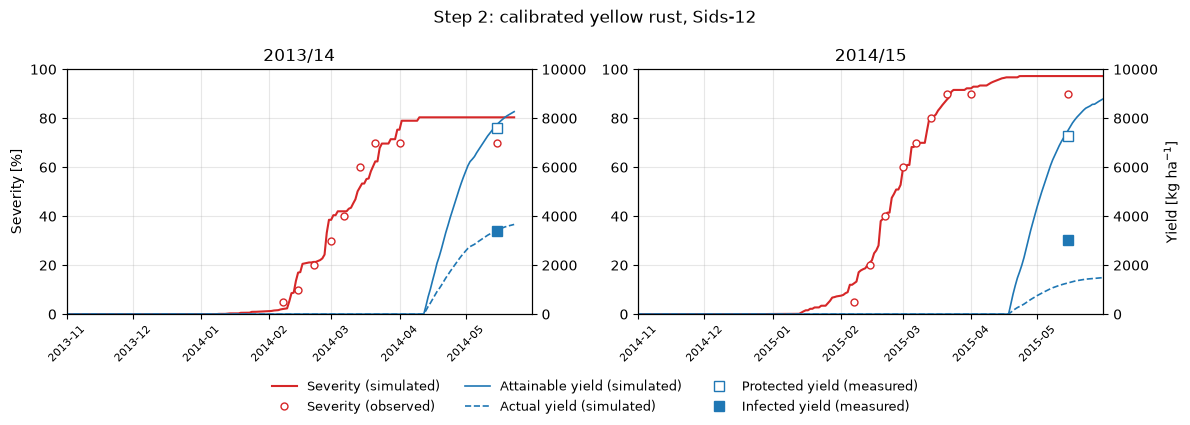

In [8]:
def plot_variety(ax, sim, variety, season, legend=False):
    """Simulated vs observed severity and yields of one cultivar-season."""
    s = sim[sim["GrowingSeason"] == season]
    r = ref_df[(ref_df["variety"] == variety) & (ref_df["year"] == season + 1)]
    ax.plot(s["Date"], s["DiseaseSeverity"], color="#d62728", lw=1.5, label="Severity (simulated)")
    sev = r.dropna(subset=["disease"])
    ax.plot(obs_dates(sev), sev["disease"], "o", color="#d62728", mfc="white", ms=5, label="Severity (observed)")
    ax.set_ylim(0, 100)
    ax2 = ax.twinx()
    ax2.plot(s["Date"], s["YieldAttainable"], color="#1f77b4", lw=1.2, label="Attainable yield (simulated)")
    ax2.plot(s["Date"], s["YieldActual"], color="#1f77b4", lw=1.2, ls="--", label="Actual yield (simulated)")
    y = r.dropna(subset=["yieldAttainable"])
    ax2.plot(obs_dates(y), y["yieldAttainable"], "s", color="#1f77b4", mfc="white", ms=7, label="Protected yield (measured)")
    ax2.plot(obs_dates(y), y["yieldActual"], "s", color="#1f77b4", ms=7, label="Infected yield (measured)")
    ax2.set_ylim(0, 10000)
    ax.set_xlim(pd.Timestamp(season, 11, 1), pd.Timestamp(season + 1, 5, 31))
    ax.tick_params(axis="x", rotation=45, labelsize=8)
    ax.grid(alpha=0.3)
    return ax2


fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
dis_sim = diag.simulation_frame(dis_res)
for ax, season in zip(axes, SEASONS):
    ax2 = plot_variety(ax, dis_sim, SUSCEPTIBLE, season)
    ax.set_title(f"{season}/{season + 1 - 2000:02d}")
axes[0].set_ylabel("Severity [%]")
ax2.set_ylabel("Yield [kg ha$^{-1}$]")
handles = axes[1].get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
fig.legend(handles, [h.get_label() for h in handles], loc="lower center", ncol=3, frameon=False, fontsize=9)
fig.suptitle("Step 2: calibrated yellow rust, Sids-12")
fig.tight_layout(rect=(0, 0.1, 1, 1))
plt.show()

## 5. Step 3 — extending to all cultivars

Every parameter is now fixed except two crop parameters, fitted per cultivar
against its severity and both yields (`calibration_variable="all"`):

- `RadiationUseEfficiency` sets the cultivar's attainable (protected) yield;
- `VarietalResistance` scales infection down (`1 − VarietalResistance`), so
  it sets how fast the epidemic grows on the cultivar.

The disease parameters, including the damage coefficient, are shared by all
cultivars, as in the vignette.

In [9]:
var_results = {}
for variety in VARIETIES:
    cfg = make_config(variety, disease_type="yellow_rust", calibration_variable="all", **CALIB)
    cfg.crop_parameters = copy.deepcopy(dis_cfg.crop_parameters)
    cfg.disease_parameters = copy.deepcopy(dis_cfg.disease_parameters)
    fr.deactivate_calibration(cfg.disease_parameters, list(cfg.disease_parameters))
    for name in ("RadiationUseEfficiency", "VarietalResistance"):
        cfg.crop_parameters[name]["calibration"] = True
    var_results[variety] = (cfg, run(cfg, variety))

pd.DataFrame({
    v: {"RMSE": res["outputs"]["summary"]["rmse"],
        **{k.split("_", 1)[1]: x for k, x in res["outputs"]["summary"]["best_params"].items()}}
    for v, (cfg, res) in var_results.items()
}).T.round(3)

- Calibrating 2 parameters with the C# multi-start simplex (3 simplexes, 999 iterations, seed 1).
- Parameters:
['crop_RadiationUseEfficiency', 'crop_VarietalResistance']


[Parallel(n_jobs=3)]: Using backend LokyBackend with 3 concurrent workers.
[Parallel(n_jobs=3)]: Done   3 out of   3 | elapsed:    5.9s finished



Best RMSE: 7.5020
{'crop_RadiationUseEfficiency': 3.025464386465484, 'crop_VarietalResistance': 0.004770609409356206}
- Calibrating 2 parameters with the C# multi-start simplex (3 simplexes, 999 iterations, seed 1).
- Parameters:
['crop_RadiationUseEfficiency', 'crop_VarietalResistance']


[Parallel(n_jobs=3)]: Using backend LokyBackend with 3 concurrent workers.
[Parallel(n_jobs=3)]: Done   3 out of   3 | elapsed:    6.2s finished



Best RMSE: 6.8320
{'crop_RadiationUseEfficiency': 3.045459818667365, 'crop_VarietalResistance': 0.11744761872721955}
- Calibrating 2 parameters with the C# multi-start simplex (3 simplexes, 999 iterations, seed 1).
- Parameters:
['crop_RadiationUseEfficiency', 'crop_VarietalResistance']


...

[Parallel(n_jobs=3)]: Using backend LokyBackend with 3 concurrent workers.
[Parallel(n_jobs=3)]: Done   3 out of   3 | elapsed:   11.5s finished



Best RMSE: 6.3680
{'crop_RadiationUseEfficiency': 2.7990452230704843, 'crop_VarietalResistance': 0.6033512800408218}
- Calibrating 2 parameters with the C# multi-start simplex (3 simplexes, 999 iterations, seed 1).
- Parameters:
['crop_RadiationUseEfficiency', 'crop_VarietalResistance']


[Parallel(n_jobs=3)]: Using backend LokyBackend with 3 concurrent workers.
[Parallel(n_jobs=3)]: Done   3 out of   3 | elapsed:    9.3s finished



Best RMSE: 5.0800
{'crop_RadiationUseEfficiency': 2.4007660318902215, 'crop_VarietalResistance': 0.7479880716772234}


,RMSE,RadiationUseEfficiency,VarietalResistance
sids12,7.502,3.025,0.005
gem11,6.832,3.045,0.117
gem7,8.212,2.637,0.273
sids13,7.294,2.645,0.497
sids1,6.826,2.439,0.411
gem9,6.368,2.799,0.603
gem10,5.080,2.401,0.748


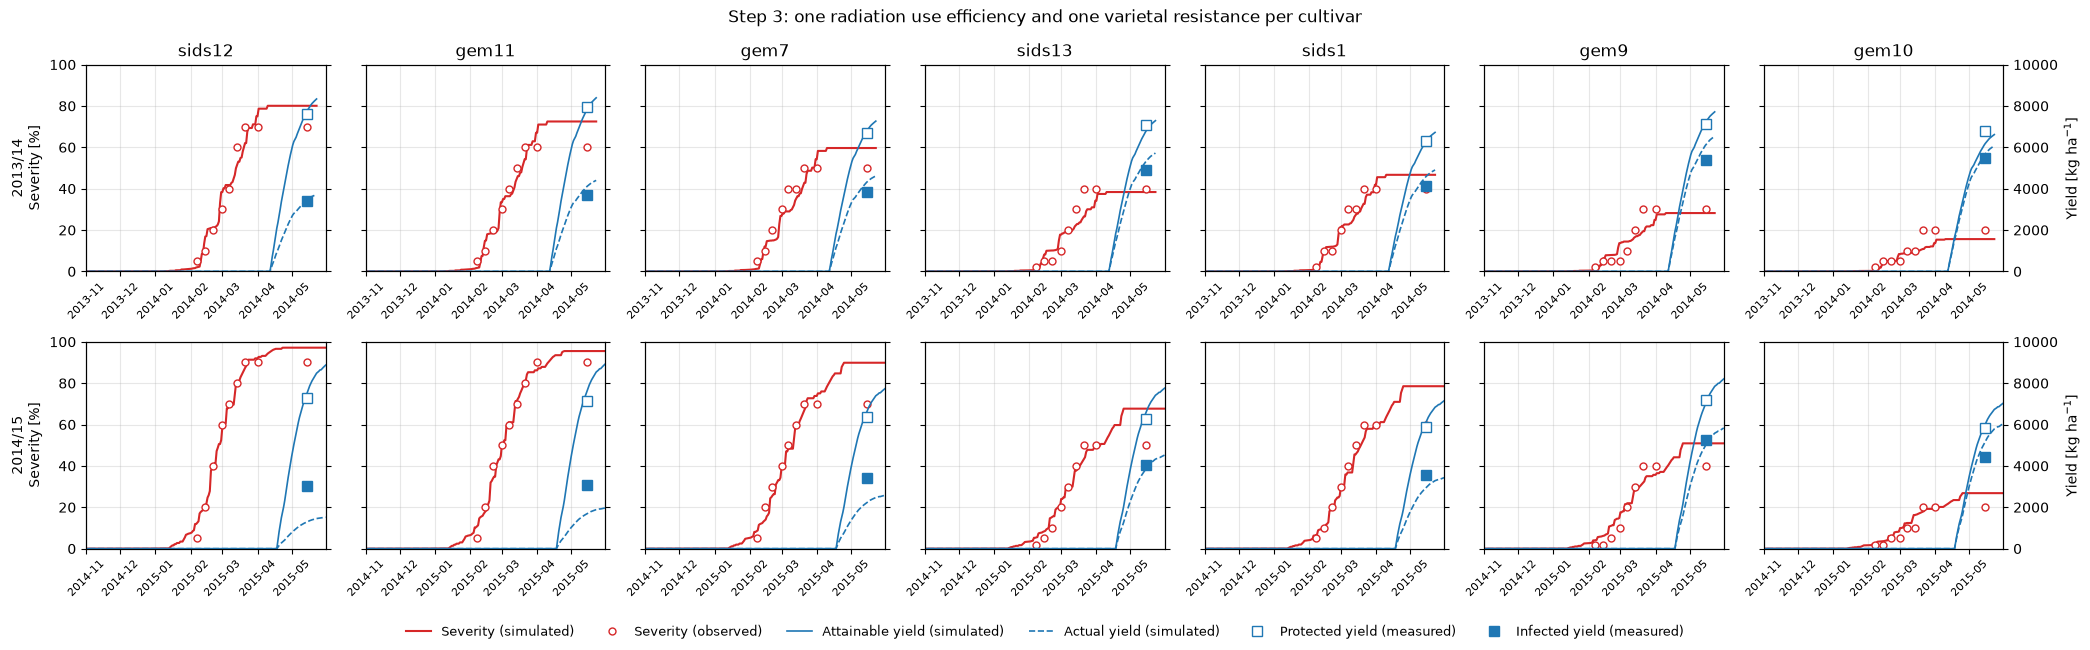

In [10]:
fig, axes = plt.subplots(2, len(VARIETIES), figsize=(3.0 * len(VARIETIES), 6.5), sharey=True)
for j, variety in enumerate(VARIETIES):
    sim = diag.simulation_frame(var_results[variety][1])
    for i, season in enumerate(SEASONS):
        ax2 = plot_variety(axes[i, j], sim, variety, season)
        if j < len(VARIETIES) - 1:
            ax2.set_yticklabels([])
        else:
            ax2.set_ylabel("Yield [kg ha$^{-1}$]")
    axes[0, j].set_title(variety)
for i, season in enumerate(SEASONS):
    axes[i, 0].set_ylabel(f"{season}/{season + 1 - 2000:02d}\nSeverity [%]")
handles = axes[0, 0].get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
fig.legend(handles, [h.get_label() for h in handles], loc="lower center", ncol=6, frameon=False, fontsize=9)
fig.suptitle("Step 3: one radiation use efficiency and one varietal resistance per cultivar")
fig.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

## 6. Simulated vs measured yield loss

The season summary of each cultivar gives its simulated attainable and actual
yield at maturity; the simulated loss is `(1 − actual / attainable) × 100`,
the same formula as the measured loss.

In [11]:
summary = pd.concat([
    fr.build_season_summary(diag.simulation_frame(res, severity_percent=False), "Sharkiya", v)
    .assign(variety=v)
    for v, (cfg, res) in var_results.items()
])
loss = (summary.rename(columns={"GrowingSeason": "season"})
        [["variety", "season", "YieldAttainable", "YieldActual", "YieldLossPerc"]]
        .merge(yield_obs[["variety", "season", "yieldAttainable", "yieldActual", "loss_measured"]],
               on=["variety", "season"]))
loss["loss_error"] = loss["YieldLossPerc"] - loss["loss_measured"]

stats = loss.groupby("season").apply(lambda d: pd.Series({
    "RMSE loss [%-pt]": np.sqrt((d["loss_error"] ** 2).mean()),
    "bias [%-pt]": d["loss_error"].mean(),
    "r": np.corrcoef(d["YieldLossPerc"], d["loss_measured"])[0, 1],
}), include_groups=False)
display(stats.round(2))
loss.set_index(["variety", "season"]).loc[VARIETIES].round(1)

,RMSE loss [%-pt],bias [%-pt],r
season,,,
2013,7.73,-7.01,1.00
2014,15.77,10.94,0.99


YieldAttainable  YieldActual  YieldLossPerc  yieldAttainable  \
variety season                                                                 
sids12  2013             8337.9       3720.5           55.4           7607.1   
        2014             8870.9       1520.8           82.9           7285.7   
gem11   2013             8393.0       4401.2           47.6           7964.3   
        2014             8929.5       1968.3           78.0           7142.9   
gem7    2013             7267.1       4615.0           36.5           6678.6   
        2014             7731.7       2580.6           66.6           6357.1   
sids13  2013             7289.1       5721.3           21.5           7071.4   
        2014             7755.1       4520.2           41.7           6250.0   
sids1   2013             6721.3       4906.2           27.0           6321.4   
        2014             7151.0       3430.9           52.0           5892.9   
gem9    2013             7713.9       6535.2           15.3           7107.1   
        2014             8207.0       5833.8           28.9           7178.6   
gem10   2013             6616.3       6077.2            8.1           6785.7   
        2014             7039.2       6051.0           14.0           5821.4   

                yieldActual  loss_measured  loss_error  
variety season                                          
sids12  2013         3392.9           55.4        -0.0  
        2014         3035.7           58.3        24.5  
gem11   2013         3714.3           53.4        -5.8  
        2014         3071.4           57.0        21.0  
gem7    2013         3821.4           42.8        -6.3  
        2014         3392.9           46.6        20.0  
sids13  2013         4892.9           30.8        -9.3  
        2014         4035.7           35.4         6.3  
sids1   2013         4107.1           35.0        -8.0  
        2014         3571.4           39.4        12.6  
gem9    2013         5392.9           24.1        -8.8  
        2014         5250.0           26.9         2.1  
gem10   2013         5500.0           18.9       -10.8  
        2014         4428.6           23.9        -9.9

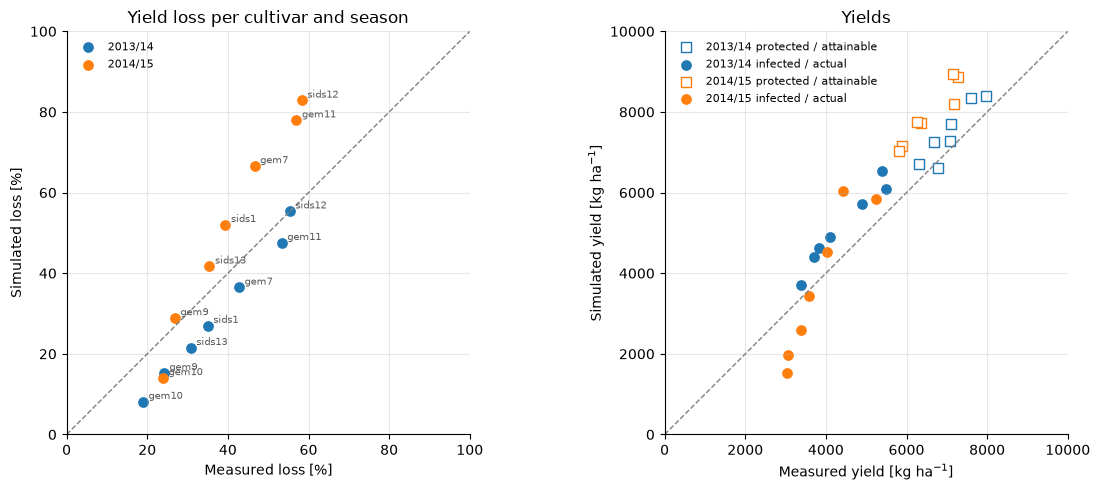

In [12]:
season_colors = {2013: "#1f77b4", 2014: "#ff7f0e"}
fig, (ax_l, ax_y) = plt.subplots(1, 2, figsize=(12, 5))

for season, d in loss.groupby("season"):
    label = f"{season}/{season + 1 - 2000:02d}"
    ax_l.scatter(d["loss_measured"], d["YieldLossPerc"], color=season_colors[season], s=45, label=label)
    for _, row in d.iterrows():
        ax_l.annotate(row["variety"], (row["loss_measured"], row["YieldLossPerc"]),
                      xytext=(4, 2), textcoords="offset points", fontsize=7, color="0.35")
    ax_y.scatter(d["yieldAttainable"], d["YieldAttainable"], color=season_colors[season], marker="s",
                 facecolors="white", s=45, label=f"{label} protected / attainable")
    ax_y.scatter(d["yieldActual"], d["YieldActual"], color=season_colors[season], s=45,
                 label=f"{label} infected / actual")

ax_l.plot([0, 100], [0, 100], color="0.5", lw=1, ls="--")
ax_l.set(xlim=(0, 100), ylim=(0, 100), xlabel="Measured loss [%]", ylabel="Simulated loss [%]",
         title="Yield loss per cultivar and season")
ax_y.plot([0, 10000], [0, 10000], color="0.5", lw=1, ls="--")
ax_y.set(xlim=(0, 10000), ylim=(0, 10000), xlabel="Measured yield [kg ha$^{-1}$]",
         ylabel="Simulated yield [kg ha$^{-1}$]", title="Yields")
for ax in (ax_l, ax_y):
    ax.set_aspect("equal")
    ax.grid(alpha=0.3)
    ax.legend(frameon=False, fontsize=8, loc="upper left")
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
fig.tight_layout()
plt.show()

In [13]:
# Severity fit per cultivar: RMSE over the observation dates the season simulates.
sev_rmse = {}
for v, (cfg, res) in var_results.items():
    err = diag.match_ref_to_sim(diag.simulation_frame(res), ref_df[ref_df["variety"] == v],
                                SEASONS, "disease", "DiseaseSeverity")
    sev_rmse[v] = err.groupby("season")["error"].apply(lambda e: np.sqrt((e ** 2).mean()))
pd.DataFrame(sev_rmse).T.round(1).rename(columns=lambda s: f"severity RMSE {s}/{s + 1 - 2000:02d}")

season,severity RMSE 2013/14,severity RMSE 2014/15
sids12,6.6,3.7
gem11,6.0,3.7
gem7,6.3,7.4
sids13,6.4,6.9
sids1,4.3,6.9
gem9,5.4,6.0
gem10,4.2,3.7


## 7. Summary and limits

**Crop (step 1).** The calibrated crop matures on 23 May 2014 and 31 May 2015
(`CycleLength` 4231 °C d, `TbaseCrop` −0.99), after the DOY 135 yield
observations, so both protected-plot yields of Sids-12 are scored (objective
4.94). Four of the eight parameters end on or next to a bound (`TbaseCrop`
and `SlopeSenescence` low, `SlopeGrowth` and `PartitioningMaximum` high), so
their values should not be read as estimates.

**Disease (step 2).** Objective 7.14. `LightStealerDamage` ends on its lower
bound (0.5) and `Rain50Detachment` near its upper one.

**Cultivars (step 3).** `VarietalResistance` orders the cultivars from Sids-12
(0.005) to Gem-10 (0.75), the order of the paper's final severity and AUDPC
(Table 1). `RadiationUseEfficiency` ranges from 2.4 to 3.0. Severity RMSE is
3.7–7.4 points per cultivar-season.

**Yield loss (section 6).**

- 2013/14: RMSE 7.7 points, bias −7.0. Sids-12 is matched (55.4 against
  55.4 %); every other cultivar is underestimated by 6–11 points.
- 2014/15: RMSE 15.8 points, bias +10.9. The three most susceptible cultivars
  are overestimated by 20–25 points (Sids-12 83 against 58 %, Gem-11 78
  against 57 %, Gem-7 67 against 47 %).
- Gem-10 is underestimated in both seasons (8 and 14 against 19 and 24 %).
- The correlation of about 1.0 within each season mostly says that simulated
  and measured loss both follow the cultivars' resistance. It is not evidence
  that the model predicts loss.

The two seasons need different damage. Observed severity was higher in
2014/15, but the measured loss only rose by about 3 points (Sids-12 55 to
58 %), while the model turns the extra severity into 27 more points of loss
(55 to 83 %). One damage coefficient, shared by all cultivars and seasons,
cannot match both.

**This is one run of a random multi-start search.** With another seed the
simplexes start elsewhere and end on other parameters, as successive C# runs
do: two runs of the C# engine on this vignette gave a loss RMSE of 8.3 and
10.0 points in one run, 7.6 and 8.1 in the other (2013/14, 2014/15).

**Limits.**

1. The loss is fitted, not predicted: both yields of every cultivar-season are
   calibration targets. A hold-out (calibrate on one season, predict the other)
   would test it, but it is not done here.
2. Sowing on DOY 300 and harvest on DOY 135 are assumptions; the paper gives
   neither date. The `fint` values are placeholders.
3. Weather is gridded (NASA POWER / MERRA-2), radiation is estimated from the
   temperature range, and hourly humidity and leaf wetness are synthesised.
4. Two seasons at one site, three replicates per treatment in the paper.
5. Measured yields are grain at market moisture (ardab feddan⁻¹); the model's
   yield is not tied to a moisture content. The loss, a ratio, is not affected.